<a href="https://www.pieriandata.com"><img src="../DATA/Logo.jpg"></a>

# Morphological Operators

In [216]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [217]:
def load_img():
    blank_img =np.zeros((600,600))
    font = cv2.FONT_HERSHEY_SIMPLEX
    cv2.putText(
        blank_img,
        text='ABCDE',
        org=(50,300), 
        fontFace=font,
        fontScale= 5,
        color=(255,255,255),
        thickness=25,
        lineType=cv2.LINE_AA
    )
    return blank_img

In [218]:
def display_img(img):
    fig = plt.figure(figsize=(12,10))
    ax = fig.add_subplot(111)
    ax.imshow(img,cmap='gray')

In [219]:
img = load_img()

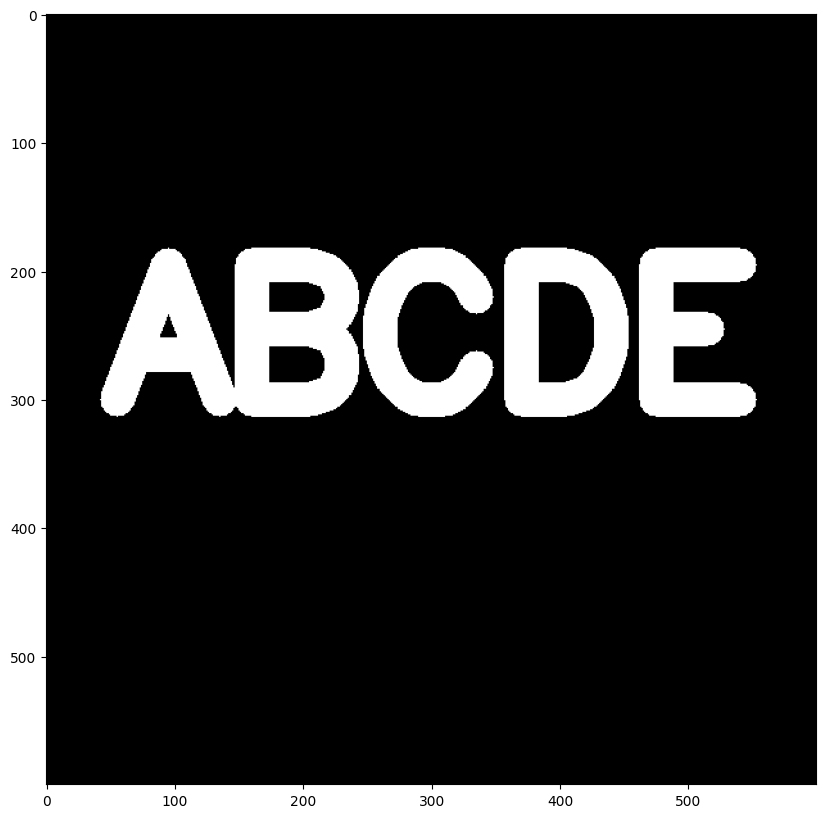

In [220]:
display_img(img)

## Erosion

Erodes away boundaries of foreground objects. Works best when foreground is light color (preferrably white) and background is dark.

In [221]:
kernel = np.ones((5,5),np.uint8)
erosion1 = cv2.erode(img , kernel, iterations=1)

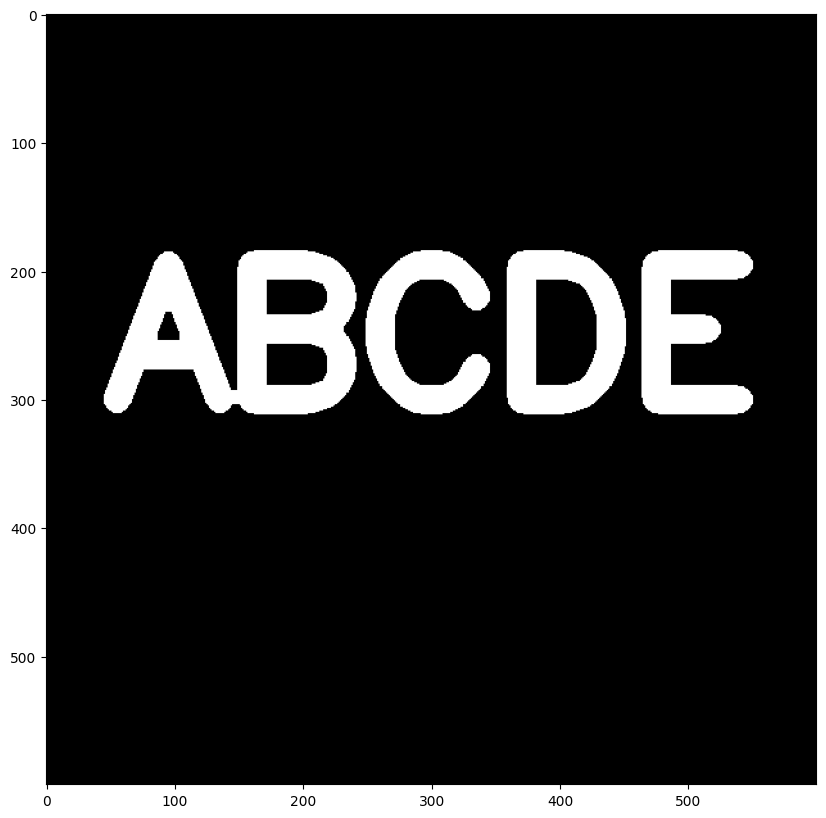

In [222]:
display_img(erosion1)

In [223]:
img = load_img()
kernel = np.ones((5,5),np.uint8)
erosion5 = cv2.erode(img,kernel,iterations = 4)

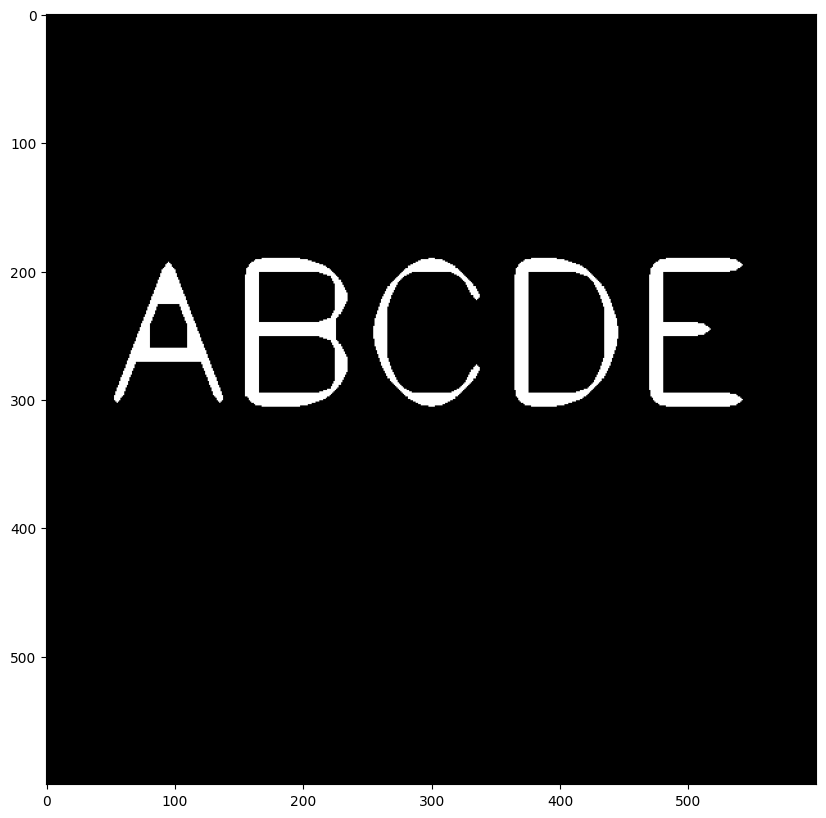

In [224]:
display_img(erosion5)

## Opening
Opening is erosion followed by dilation. Useful in removing background noise!

In [225]:
img = load_img()

In [226]:
white_noise = np.random.randint(low=0,high=2,size=(600,600))

In [227]:
white_noise

array([[1, 1, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 1, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       ...,
       [1, 0, 1, ..., 0, 0, 1],
       [1, 0, 0, ..., 1, 0, 1],
       [0, 1, 0, ..., 1, 0, 0]], shape=(600, 600), dtype=int32)

In [228]:
white_noise = white_noise*255

In [229]:
white_noise.shape

(600, 600)

In [230]:
img.shape

(600, 600)

In [231]:
noise_img = white_noise+img

In [232]:
noise_img.max()

np.float64(510.0)

In [233]:
# noise_img[noise_img>255] = 255

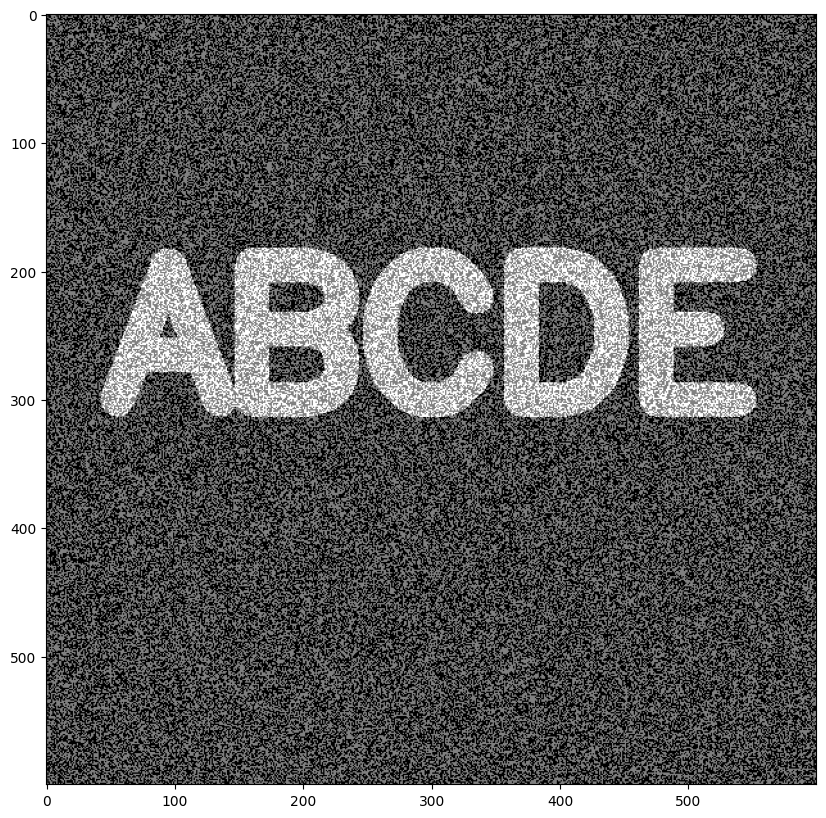

In [234]:
display_img(noise_img)

In [235]:
opening = cv2.morphologyEx(noise_img, cv2.MORPH_OPEN, kernel)

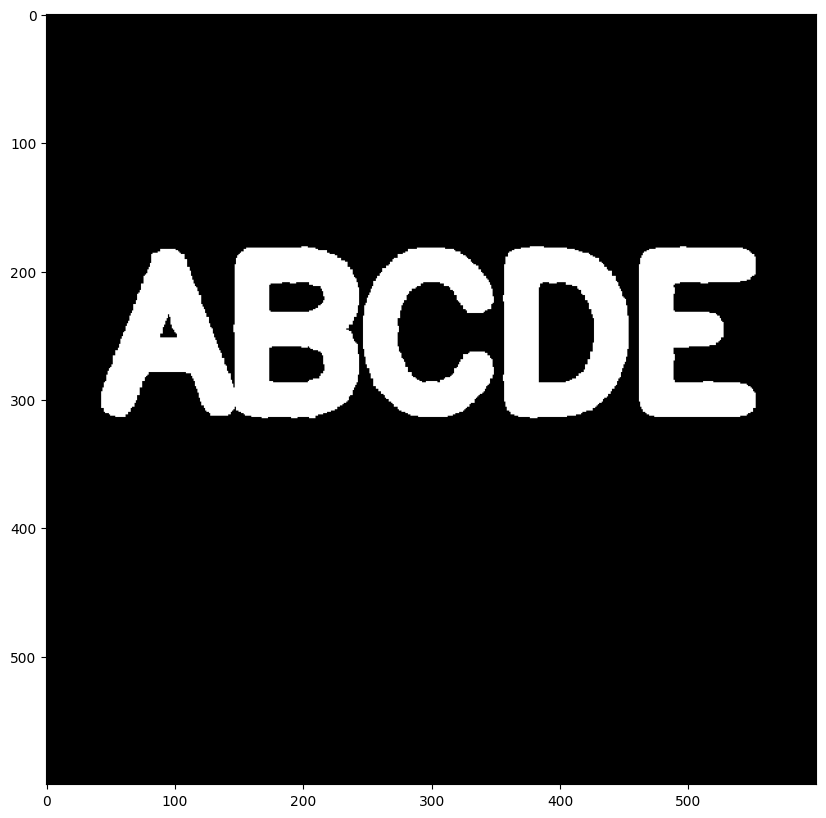

In [236]:
display_img(opening)

### Closing
 Useful in removing noise from foreground objects, such as black dots on top of the white text.

In [237]:
img = load_img()

In [238]:
black_noise = np.random.randint(low=0,high=2,size=(600,600))

In [239]:
black_noise

array([[0, 0, 0, ..., 0, 0, 1],
       [1, 1, 1, ..., 0, 0, 0],
       [1, 0, 0, ..., 1, 0, 0],
       ...,
       [1, 0, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 1, ..., 0, 0, 1]], shape=(600, 600), dtype=int32)

In [240]:
black_noise= black_noise * -255

In [241]:
black_noise_img = img + black_noise

In [242]:
black_noise_img

array([[   0.,    0.,    0., ...,    0.,    0., -255.],
       [-255., -255., -255., ...,    0.,    0.,    0.],
       [-255.,    0.,    0., ..., -255.,    0.,    0.],
       ...,
       [-255.,    0.,    0., ..., -255., -255.,    0.],
       [   0.,    0.,    0., ..., -255.,    0.,    0.],
       [   0.,    0., -255., ...,    0.,    0., -255.]], shape=(600, 600))

In [243]:
black_noise_img[black_noise_img==-255] = 0

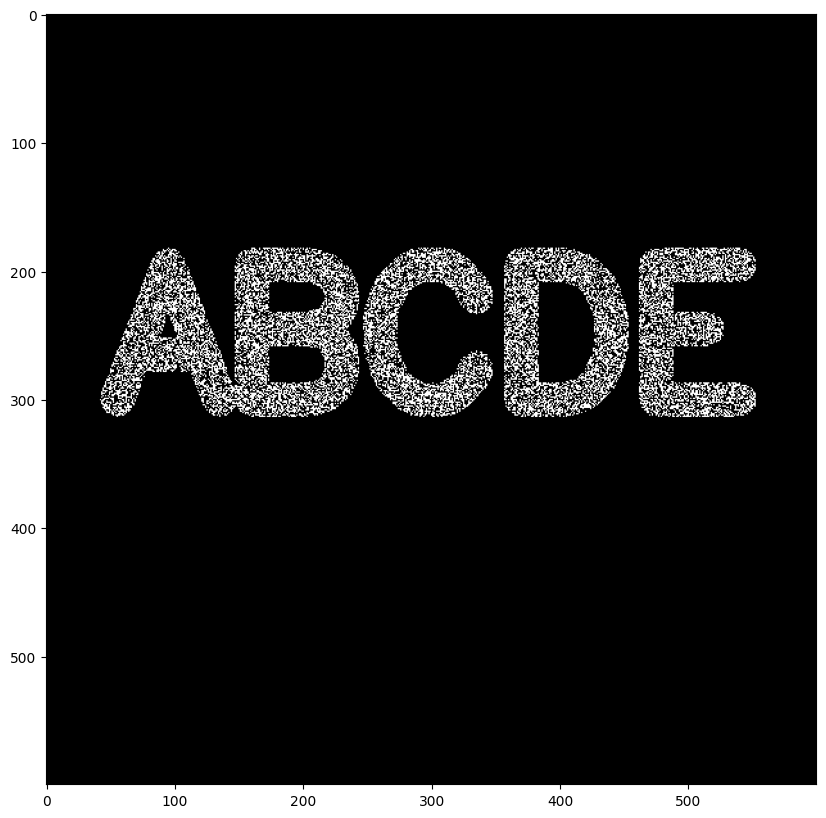

In [244]:
display_img(black_noise_img)

In [245]:
closing = cv2.morphologyEx(black_noise_img, cv2.MORPH_CLOSE, kernel)

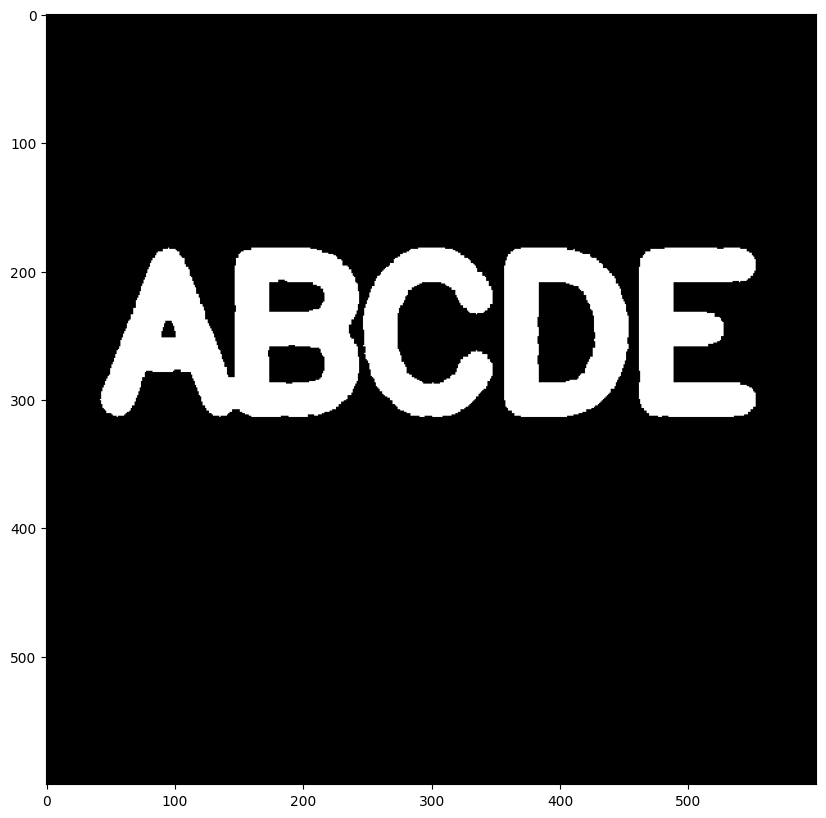

In [246]:
display_img(closing)

## Morphological Gradient

Difference between dilation and erosion of an image.

In [247]:
img = load_img()

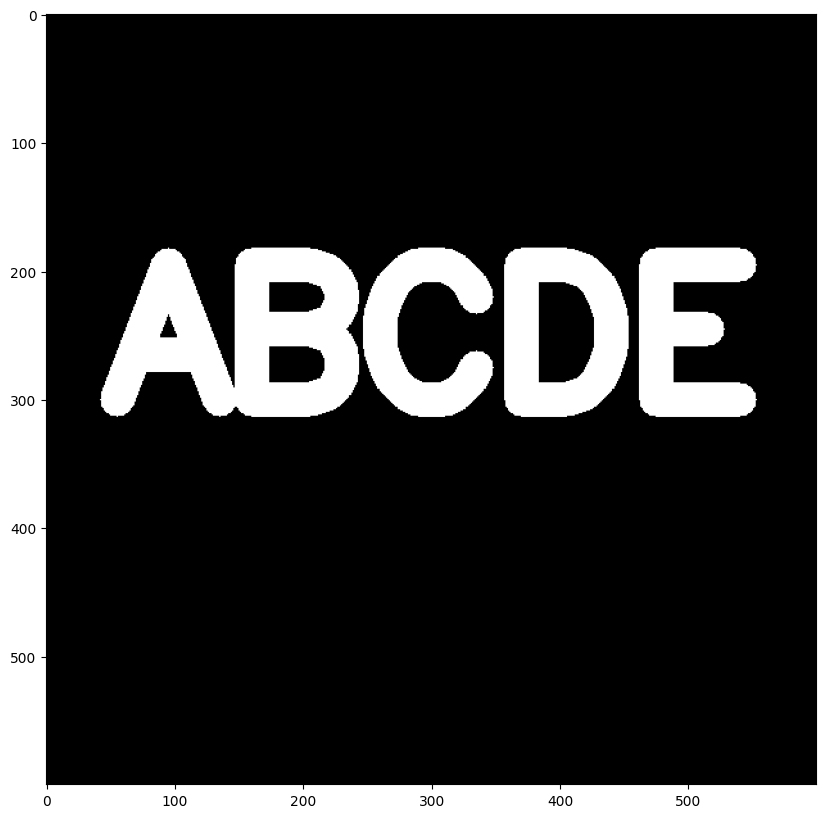

In [248]:
display_img(img)

In [249]:
gradient = cv2.morphologyEx(img,cv2.MORPH_GRADIENT,kernel)

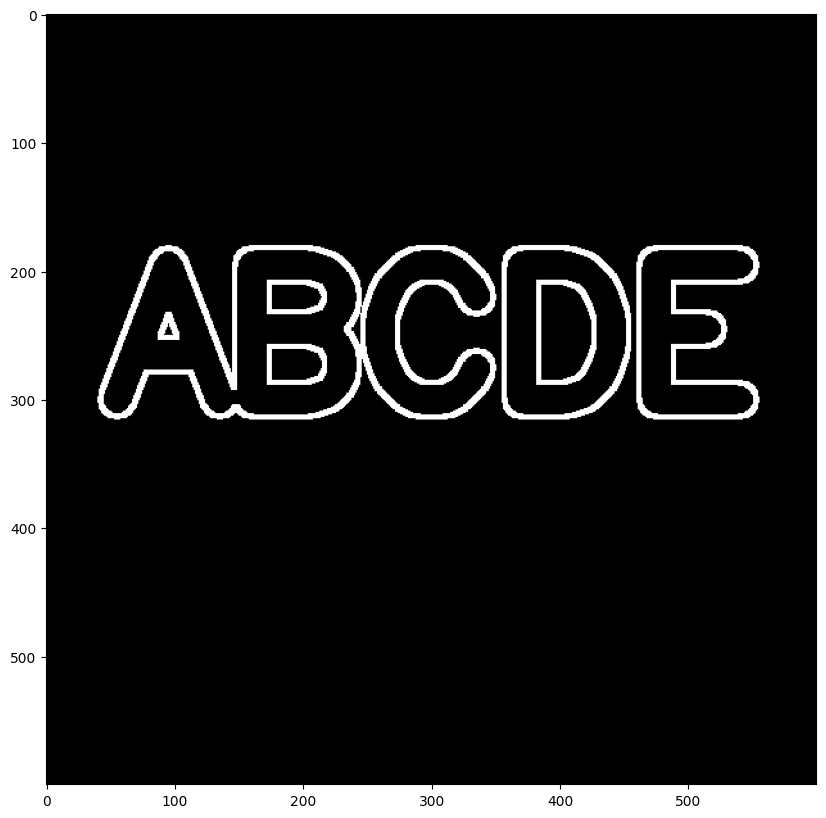

In [250]:
display_img(gradient)

# Great work!